# Loan Default Prediction Using Logistic Regression


## Imports and Reproducibility

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

DATA_PATH = "train.csv"
TARGET = "Loan Status"

np.set_printoptions(suppress=True, precision=4)
pd.set_option("display.max_columns", 100)

## Load and Understand the Dataset

In [50]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nTarget counts:")
display(df[TARGET].value_counts(dropna=False).sort_index().to_frame("count"))

print("\nTarget proportions:")
display((df[TARGET].value_counts(normalize=True).sort_index() * 100).to_frame("percent"))

Dataset shape: (67463, 35)

First five rows:


,ID,Loan Amount,Funded Amount,Funded Amount Investor,Term,Batch Enrolled,Interest Rate,Grade,Sub Grade,Employment Duration,Home Ownership,Verification Status,Payment Plan,Loan Title,Debit to Income,Delinquency - two years,Inquires - six months,Open Account,Public Record,Revolving Balance,Revolving Utilities,Total Accounts,Initial List Status,Total Received Interest,Total Received Late Fee,Recoveries,Collection Recovery Fee,Collection 12 months Medical,Application Type,Last week Pay,Accounts Delinquent,Total Collection Amount,Total Current Balance,Total Revolving Credit Limit,Loan Status
0,65087372,10000,32236,12329.36286,59,BAT2522922,11.135007,B,C4,MORTGAGE,176346.62670,Not Verified,n,Debt Consolidation,16.284758,1,0,13,0,24246,74.932551,7,w,2929.646315,0.102055,2.498291,0.793724,0,INDIVIDUAL,49,0,31,311301,6619,0
1,1450153,3609,11940,12191.99692,59,BAT1586599,12.237563,C,D3,RENT,39833.92100,Source Verified,n,Debt consolidation,15.412409,0,0,12,0,812,78.297186,13,f,772.769385,0.036181,2.377215,0.974821,0,INDIVIDUAL,109,0,53,182610,20885,0
2,1969101,28276,9311,21603.22455,59,BAT2136391,12.545884,F,D4,MORTGAGE,91506.69105,Source Verified,n,Debt Consolidation,28.137619,0,0,14,0,1843,2.073040,20,w,863.324396,18.778660,4.316277,1.020075,0,INDIVIDUAL,66,0,34,89801,26155,0
3,6651430,11170,6954,17877.15585,59,BAT2428731,16.731201,C,C3,MORTGAGE,108286.57590,Source Verified,n,Debt consolidation,18.043730,1,0,7,0,13819,67.467951,12,w,288.173196,0.044131,0.107020,0.749971,0,INDIVIDUAL,39,0,40,9189,60214,0
4,14354669,16890,13226,13539.92667,59,BAT5341619,15.008300,C,D4,MORTGAGE,44234.82545,Source Verified,n,Credit card refinancing,17.209886,1,3,13,1,1544,85.250761,22,w,129.239553,19.306646,1294.818751,0.368953,0,INDIVIDUAL,18,0,430,126029,22579,0



Data types:


,dtype
ID,int64
Loan Amount,int64
Funded Amount,int64
Funded Amount Investor,float64
Term,int64
Batch Enrolled,object
Interest Rate,float64
Grade,object
Sub Grade,object
Employment Duration,object



Target counts:


,count
Loan Status,
0,61222
1,6241



Target proportions:


,percent
Loan Status,
0,90.749003
1,9.250997


In [51]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(missing_summary.head(15))

Total missing values: 0
Duplicate rows: 0


,missing_count,missing_percent
ID,0,0.0
Collection Recovery Fee,0,0.0
Revolving Utilities,0,0.0
Total Accounts,0,0.0
Initial List Status,0,0.0
Total Received Interest,0,0.0
Total Received Late Fee,0,0.0
Recoveries,0,0.0
Collection 12 months Medical,0,0.0
Public Record,0,0.0


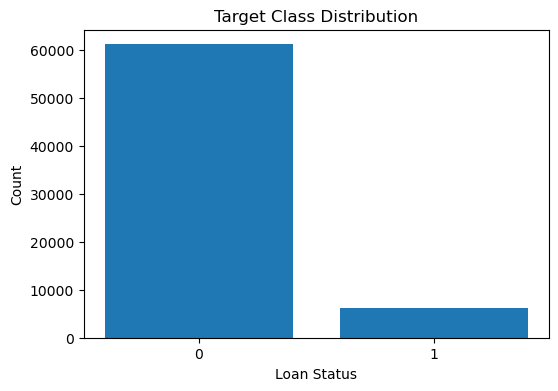

Majority class: 0
Majority-class baseline accuracy: 0.9075


In [52]:
target_counts = df[TARGET].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.title("Target Class Distribution")
plt.show()

majority_class = df[TARGET].mode()[0]
majority_baseline_accuracy = (df[TARGET] == majority_class).mean()

print("Majority class:", majority_class)
print(f"Majority-class baseline accuracy: {majority_baseline_accuracy:.4f}")

## Define Prediction Time and Remove Inappropriate Features

In [53]:
DROP_COLUMNS = [
    "ID",
    "Batch Enrolled",
    "Loan Title",
    "Payment Plan",
    "Accounts Delinquent",
    "Total Received Interest",
    "Total Received Late Fee",
    "Recoveries",
    "Collection Recovery Fee",
    "Last week Pay",
    "Total Collection Amount",
]

existing_drop_columns = [c for c in DROP_COLUMNS if c in df.columns]

model_df = df.drop(columns=existing_drop_columns).copy()
model_df = model_df.dropna(subset=[TARGET]).reset_index(drop=True)

print("Dropped columns:")
print(existing_drop_columns)
print("\nModel dataframe shape:", model_df.shape)

Dropped columns:
['ID', 'Batch Enrolled', 'Loan Title', 'Payment Plan', 'Accounts Delinquent', 'Total Received Interest', 'Total Received Late Fee', 'Recoveries', 'Collection Recovery Fee', 'Last week Pay', 'Total Collection Amount']

Model dataframe shape: (67463, 24)


## Model training, Validation and Test Split

In [54]:
def stratified_split_indices(y, train_ratio=0.70, val_ratio=0.15, seed=42):
    local_rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []

    y = np.asarray(y)

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        local_rng.shuffle(idx)

        n = len(idx)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)

        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train+n_val])
        test_idx.extend(idx[n_train+n_val:])

    train_idx = np.array(train_idx)
    val_idx = np.array(val_idx)
    test_idx = np.array(test_idx)

    local_rng.shuffle(train_idx)
    local_rng.shuffle(val_idx)
    local_rng.shuffle(test_idx)

    return train_idx, val_idx, test_idx

y_all = model_df[TARGET].astype(int).to_numpy()
X_raw = model_df.drop(columns=[TARGET]).copy()

train_idx, val_idx, test_idx = stratified_split_indices(y_all, seed=SEED)

X_train_raw = X_raw.iloc[train_idx].reset_index(drop=True)
X_val_raw = X_raw.iloc[val_idx].reset_index(drop=True)
X_test_raw = X_raw.iloc[test_idx].reset_index(drop=True)

y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

print("Train:", X_train_raw.shape, np.bincount(y_train))
print("Validation:", X_val_raw.shape, np.bincount(y_val))
print("Test:", X_test_raw.shape, np.bincount(y_test))

Train: (47223, 23) [42855  4368]
Validation: (10119, 23) [9183  936]
Test: (10121, 23) [9184  937]


## Leakage-Aware Preprocessing

In [55]:
categorical_cols = X_train_raw.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_cols = X_train_raw.select_dtypes(include=[np.number]).columns.tolist()

print("Categorical predictors:", categorical_cols)
print("Number of numerical predictors:", len(numeric_cols))

Categorical predictors: ['Grade', 'Sub Grade', 'Employment Duration', 'Verification Status', 'Initial List Status', 'Application Type']
Number of numerical predictors: 17


In [56]:
def fit_preprocessor(X_train):
    categorical = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
    numerical = X_train.select_dtypes(include=[np.number]).columns.tolist()

    numeric_medians = X_train[numerical].median()

    train_num = X_train[numerical].fillna(numeric_medians)
    means = train_num.mean()
    stds = train_num.std(ddof=0).replace(0, 1.0)

    train_cat = pd.get_dummies(
        X_train[categorical].fillna("__MISSING__"),
        columns=categorical,
        drop_first=False,
        dtype=float
    )

    category_columns = train_cat.columns.tolist()

    return {
        "categorical": categorical,
        "numerical": numerical,
        "numeric_medians": numeric_medians,
        "means": means,
        "stds": stds,
        "category_columns": category_columns,
    }

def transform_with_preprocessor(X, prep):
    numerical = prep["numerical"]
    categorical = prep["categorical"]

    X_num = X[numerical].fillna(prep["numeric_medians"])
    X_num = (X_num - prep["means"]) / prep["stds"]

    X_cat = pd.get_dummies(
        X[categorical].fillna("__MISSING__"),
        columns=categorical,
        drop_first=False,
        dtype=float
    )
    X_cat = X_cat.reindex(columns=prep["category_columns"], fill_value=0.0)

    transformed = pd.concat(
        [X_num.reset_index(drop=True), X_cat.reset_index(drop=True)],
        axis=1
    )

    return transformed.astype(float)

prep = fit_preprocessor(X_train_raw)

X_train_df = transform_with_preprocessor(X_train_raw, prep)
X_val_df = transform_with_preprocessor(X_val_raw, prep)
X_test_df = transform_with_preprocessor(X_test_raw, prep)

X_train = X_train_df.to_numpy(dtype=float)
X_val = X_val_df.to_numpy(dtype=float)
X_test = X_test_df.to_numpy(dtype=float)

feature_names = X_train_df.columns.tolist()

print("Processed train shape:", X_train.shape)
print("Processed validation shape:", X_val.shape)
print("Processed test shape:", X_test.shape)
print("Number of model features:", len(feature_names))

Processed train shape: (47223, 69)
Processed validation shape: (10119, 69)
Processed test shape: (10121, 69)
Number of model features: 69


## 7. Sanity Checks

In [57]:
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert not np.isnan(X_train).any()
assert not np.isnan(X_val).any()
assert not np.isnan(X_test).any()
assert set(np.unique(y_train)).issubset({0, 1})

print("All preprocessing sanity checks passed.")

All preprocessing sanity checks passed.


##  Implementation of Sigmoid and BCE

In [58]:
def sigmoid(z):
    # Clipping prevents numerical overflow in exp for extreme scores.
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def binary_cross_entropy(y_true, y_prob, positive_weight=1.0):
    eps = 1e-12
    y_prob = np.clip(y_prob, eps, 1.0 - eps)

    losses = -(
        positive_weight * y_true * np.log(y_prob)
        + (1 - y_true) * np.log(1 - y_prob)
    )
    return np.mean(losses)

print("sigmoid(0) =", sigmoid(np.array([0.0]))[0])
assert 0 <= sigmoid(np.array([-5.0]))[0] <= 1
assert 0 <= sigmoid(np.array([5.0]))[0] <= 1

sigmoid(0) = 0.5


## Logistic Regression Class Implemented

In [ ]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.05, epochs=500, positive_weight=1.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.positive_weight = positive_weight
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def _linear_score(self, X):
        return X @ self.weights + self.bias

    def predict_proba(self, X):
        return sigmoid(self._linear_score(X))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):
            # Forward pass
            z = self._linear_score(X)
            y_prob = sigmoid(z)

            # Loss
            loss = binary_cross_entropy(
                y,
                y_prob,
                positive_weight=self.positive_weight
            )
            self.loss_history.append(loss)

            
            sample_weight = np.where(y == 1, self.positive_weight, 1.0)
            error = sample_weight * (y_prob - y)

            dw = (X.T @ error) / n_samples
            db = np.mean(error)

           
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return self

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

##  Evaluation Metrics Implemented

In [60]:
def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    return tn, fp, fn, tp

def classification_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_counts(y_true, y_pred)

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-15)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }

def roc_auc_from_scratch(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    order = np.argsort(scores)
    sorted_scores = scores[order]

    ranks = np.empty(len(scores), dtype=float)
    i = 0
    while i < len(scores):
        j = i
        while j + 1 < len(scores) and sorted_scores[j + 1] == sorted_scores[i]:
            j += 1
        average_rank = ((i + 1) + (j + 1)) / 2.0
        ranks[order[i:j+1]] = average_rank
        i = j + 1

    positives = y_true == 1
    n_pos = np.sum(positives)
    n_neg = len(y_true) - n_pos

    if n_pos == 0 or n_neg == 0:
        return np.nan

    rank_sum_pos = np.sum(ranks[positives])
    auc = (rank_sum_pos - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    return float(auc)

## Majority-Class Baseline on Validation Data

In [61]:
val_majority = int(pd.Series(y_train).mode()[0])
val_baseline_pred = np.full_like(y_val, val_majority)

baseline_metrics = classification_metrics(y_val, val_baseline_pred)
display(pd.DataFrame([baseline_metrics], index=["Majority baseline"]))

,accuracy,precision,recall,f1,tn,fp,fn,tp
Majority baseline,0.907501,0.0,0.0,0.0,9183,0,936,0


##  Learning-Rate Experiment

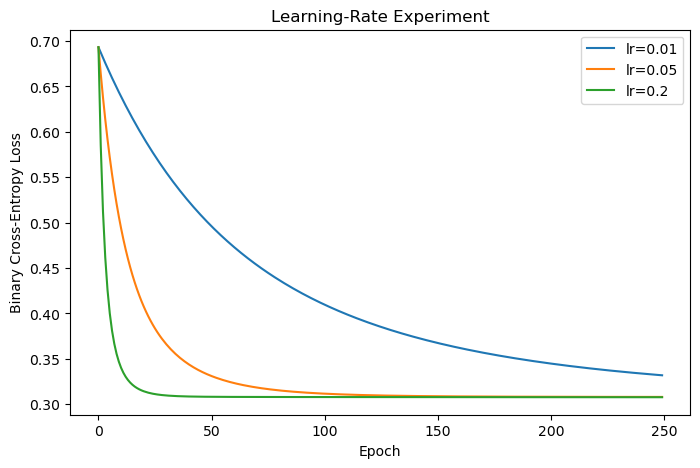

lr=0.01: initial loss=0.693147, final loss=0.331947
lr=0.05: initial loss=0.693147, final loss=0.308122
lr=0.20: initial loss=0.693147, final loss=0.307793


In [62]:
learning_rates = [0.01, 0.05, 0.20]
lr_models = {}

plt.figure(figsize=(8, 5))

for lr in learning_rates:
    model = LogisticRegressionScratch(
        learning_rate=lr,
        epochs=250,
        positive_weight=1.0
    )
    model.fit(X_train, y_train)
    lr_models[lr] = model
    plt.plot(model.loss_history, label=f"lr={lr}")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Learning-Rate Experiment")
plt.legend()
plt.show()

for lr, model in lr_models.items():
    print(
        f"lr={lr:.2f}: "
        f"initial loss={model.loss_history[0]:.6f}, "
        f"final loss={model.loss_history[-1]:.6f}"
    )

##  Training Unweighted Model

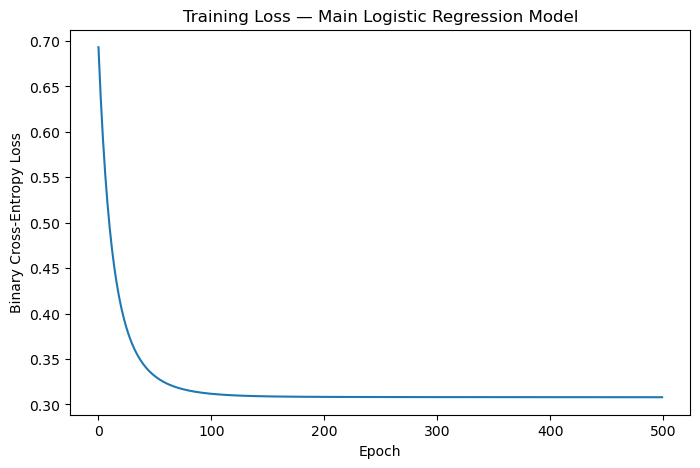

Initial loss: 0.6931471805599453
Final loss: 0.3079257784928602


In [63]:
main_model = LogisticRegressionScratch(
    learning_rate=0.05,
    epochs=500,
    positive_weight=1.0
)

main_model.fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(main_model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss — Main Logistic Regression Model")
plt.show()

print("Initial loss:", main_model.loss_history[0])
print("Final loss:", main_model.loss_history[-1])

## Selected threshold of 0.50

In [64]:
val_prob = main_model.predict_proba(X_val)
val_pred_050 = (val_prob >= 0.50).astype(int)

metrics_050 = classification_metrics(y_val, val_pred_050)
auc_unweighted = roc_auc_from_scratch(y_val, val_prob)

result_050 = pd.DataFrame([{
    **metrics_050,
    "roc_auc": auc_unweighted
}], index=["Unweighted @ 0.50"])

display(result_050)

print("Probability range:", float(val_prob.min()), "to", float(val_prob.max()))

,accuracy,precision,recall,f1,tn,fp,fn,tp,roc_auc
Unweighted @ 0.50,0.907501,0.0,0.0,0.0,9183,0,936,0,0.528733


Probability range: 0.07075384734682817 to 0.1850381757374806


## Classification-Threshold Experiment

In [65]:
thresholds = np.arange(0.05, 0.701, 0.025)

threshold_rows = []

for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)
    m = classification_metrics(y_val, pred)

    threshold_rows.append({
        "threshold": threshold,
        **m
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results)

,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp
0,0.050,0.092499,0.092499,1.000000,0.169335,0,9183,0,936
1,0.075,0.097638,0.092491,0.993590,0.169229,58,9125,6,930
2,0.100,0.745232,0.112370,0.254274,0.155861,7303,1880,698,238
3,0.125,0.899200,0.125000,0.014957,0.026718,9085,98,922,14
4,0.150,0.906513,0.187500,0.003205,0.006303,9170,13,933,3
5,0.175,0.907303,0.250000,0.001068,0.002128,9180,3,935,1
6,0.200,0.907501,0.000000,0.000000,0.000000,9183,0,936,0
7,0.225,0.907501,0.000000,0.000000,0.000000,9183,0,936,0
8,0.250,0.907501,0.000000,0.000000,0.000000,9183,0,936,0
9,0.275,0.907501,0.000000,0.000000,0.000000,9183,0,936,0


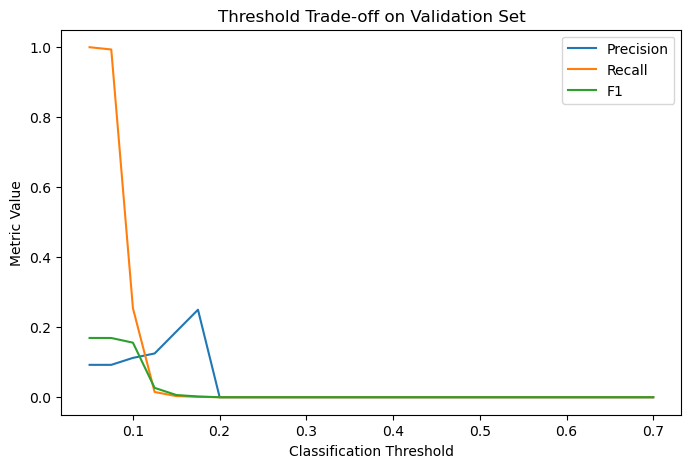

Threshold selected using validation F1: 0.050


,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp
0,0.05,0.092499,0.092499,1.0,0.169335,0,9183,0,936


In [66]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_results["threshold"], threshold_results["precision"], label="Precision")
plt.plot(threshold_results["threshold"], threshold_results["recall"], label="Recall")
plt.plot(threshold_results["threshold"], threshold_results["f1"], label="F1")
plt.xlabel("Classification Threshold")
plt.ylabel("Metric Value")
plt.title("Threshold Trade-off on Validation Set")
plt.legend()
plt.show()

best_idx = threshold_results["f1"].idxmax()
selected_threshold = float(threshold_results.loc[best_idx, "threshold"])

print(f"Threshold selected using validation F1: {selected_threshold:.3f}")
display(threshold_results.loc[[best_idx]])

## Class-Weighted Binary Cross-Entropy Loss 

In [43]:
n0 = np.sum(y_train == 0)
n1 = np.sum(y_train == 1)
positive_weight = n0 / n1

print("Class 0 training observations:", n0)
print("Class 1 training observations:", n1)
print("Positive-class weight:", positive_weight)

weighted_model = LogisticRegressionScratch(
    learning_rate=0.05,
    epochs=500,
    positive_weight=positive_weight
)

weighted_model.fit(X_train, y_train)

weighted_val_prob = weighted_model.predict_proba(X_val)
weighted_val_pred = (weighted_val_prob >= 0.50).astype(int)

weighted_metrics = classification_metrics(y_val, weighted_val_pred)
weighted_auc = roc_auc_from_scratch(y_val, weighted_val_prob)

display(pd.DataFrame([{
    **weighted_metrics,
    "roc_auc": weighted_auc
}], index=["Weighted BCE @ 0.50"]))

Class 0 training observations: 42855
Class 1 training observations: 4368
Positive-class weight: 9.811126373626374


,accuracy,precision,recall,f1,tn,fp,fn,tp,roc_auc
Weighted BCE @ 0.50,0.535527,0.097519,0.487179,0.162509,4963,4220,480,456,0.523457


## Compare the Main Validation Strategies

In [44]:
selected_pred = (val_prob >= selected_threshold).astype(int)

comparison = pd.DataFrame([
    {
        "model": "Unweighted BCE",
        "threshold": 0.50,
        **classification_metrics(y_val, val_pred_050),
        "roc_auc": auc_unweighted,
    },
    {
        "model": "Unweighted BCE",
        "threshold": selected_threshold,
        **classification_metrics(y_val, selected_pred),
        "roc_auc": auc_unweighted,
    },
    {
        "model": "Weighted BCE",
        "threshold": 0.50,
        **classification_metrics(y_val, weighted_val_pred),
        "roc_auc": weighted_auc,
    },
])

display(comparison)

,model,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp,roc_auc
0,Unweighted BCE,0.50,0.907501,0.000000,0.000000,0.000000,9183,0,936,0,0.528733
1,Unweighted BCE,0.05,0.092499,0.092499,1.000000,0.169335,0,9183,0,936,0.528733
2,Weighted BCE,0.50,0.535527,0.097519,0.487179,0.162509,4963,4220,480,456,0.523457


## Final Model Test 

In [45]:
test_prob = main_model.predict_proba(X_test)
test_pred = (test_prob >= selected_threshold).astype(int)

test_metrics = classification_metrics(y_test, test_pred)
test_auc = roc_auc_from_scratch(y_test, test_prob)

final_test_results = pd.DataFrame([{
    "threshold": selected_threshold,
    **test_metrics,
    "roc_auc": test_auc
}], index=["Final held-out test"])

display(final_test_results)

,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp,roc_auc
Final held-out test,0.05,0.09258,0.09258,1.0,0.16947,0,9184,0,937,0.512637


## Final Confusion Model Matrix

,Predicted 0,Predicted 1
Actual 0,0,9184
Actual 1,0,937


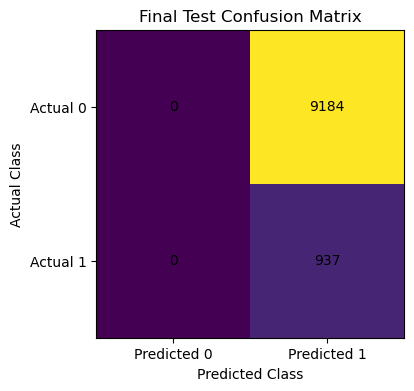

In [46]:
tn, fp, fn, tp = confusion_counts(y_test, test_pred)

confusion_matrix_df = pd.DataFrame(
    [[tn, fp],
     [fn, tp]],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

display(confusion_matrix_df)

plt.figure(figsize=(5, 4))
plt.imshow(confusion_matrix_df.values)
plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Final Test Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, confusion_matrix_df.values[i, j],
                 ha="center", va="center")

plt.show()

## Inspect Learned Coeficients

In [47]:
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": main_model.weights
})

coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
coefficient_table = coefficient_table.sort_values(
    "absolute_coefficient",
    ascending=False
)

display(coefficient_table.head(20))

,feature,coefficient,absolute_coefficient
67,Application Type_INDIVIDUAL,-0.647694,0.647694
66,Initial List Status_w,-0.356158,0.356158
59,Employment Duration_MORTGAGE,-0.313352,0.313352
65,Initial List Status_f,-0.295968,0.295968
63,Verification Status_Source Verified,-0.257629,0.257629
61,Employment Duration_RENT,-0.242436,0.242436
62,Verification Status_Not Verified,-0.202516,0.202516
64,Verification Status_Verified,-0.191982,0.191982
18,Grade_B,-0.183924,0.183924
19,Grade_C,-0.172126,0.172126


## Final Model Expected Behaviour VS Actual Behaviour

In [48]:
summary = {
    "initial_training_loss": main_model.loss_history[0],
    "final_training_loss": main_model.loss_history[-1],
    "validation_auc": auc_unweighted,
    "selected_threshold": selected_threshold,
    "final_test_accuracy": test_metrics["accuracy"],
    "final_test_precision": test_metrics["precision"],
    "final_test_recall": test_metrics["recall"],
    "final_test_f1": test_metrics["f1"],
    "final_test_auc": test_auc,
}
display(pd.DataFrame([summary]))

,initial_training_loss,final_training_loss,validation_auc,selected_threshold,final_test_accuracy,final_test_precision,final_test_recall,final_test_f1,final_test_auc
0,0.693147,0.307926,0.528733,0.05,0.09258,0.09258,1.0,0.16947,0.512637
